In [8]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy import stats
from scipy.integrate import quad
from scipy.interpolate import UnivariateSpline
import seaborn as sns
from scipy.special import factorial
import math
from iminuit import cost, Minuit 
import numpy as np
import pickle

sns.set_context('talk', font_scale=1.0)
sns.set_palette('colorblind')

from depth_helpers import *

Cs_line = source_dict['Cs137']

datpath = '/Users/Sophie/Desktop/COSI/calibrations/Data/CalibratedDATs/'
plot_dir = '/Users/Sophie/Desktop/COSI/calibrations/Data/trapping_figures/'

############ files contain gaussian mean of CTD value for illumination on AC and Dc side respectively, for each pixel ##############

AC_illumination_CTD = '/Users/Sophie/Desktop/COSI/calibrations/Data/CTD_params/20262201_Am241_AC_1200V_80K_57keV_to_62keV/CTD_parameters.txt'
DC_illumination_CTD = '/Users/Sophie/Desktop/COSI/calibrations/Data/CTD_params/20262201_Am241_DC_1200V_80K_57keV_to_62keV/CTD_parameters.txt'


CTD_sims = '/Users/Sophie/Desktop/COSI/calibrations/Data/SimulatedCSVs/HP41520_1/CTD_HP415201.csv'
AC_sim_events = '/Users/Sophie/Desktop/COSI/calibrations/Data/SimulatedCSVs/HP41520_1/am241_interactions_HP415201_ac.csv'
DC_sim_events = '/Users/Sophie/Desktop/COSI/calibrations/Data/SimulatedCSVs/HP41520_1/am241_interactions_HP415201_dc.csv'
sim_dCCE_path = '/Users/Sophie/Desktop/COSI/calibrations/Data/SimulatedCSVs/HP41520_1/HP415201_dCCE_1000cm.csv'

########## defined in depth helpers #################################
####### add noise to simulated CTD distribs in each pixel until the simulation matches the data (aka has the mu, sigma of the characterized data)
calibrator = DepthCalibrator_Am241(AC_illumination_CTD, DC_illumination_CTD, AC_sim_events, DC_sim_events, CTD_sims)

sim_depth, sim_ctd = calibrator.get_simdata()


sim_dCCE = np.loadtxt(sim_dCCE_path, delimiter=',').T
depth_grid = sim_dCCE[0]
print(sim_dCCE)
### In these, b=electron trapping, c=hole trapping
def e_cce(b, c):
    ### electron-dominated signal
    return (1.-b*sim_dCCE[1][::-1])*(1.-c*sim_dCCE[2][::-1])
def h_cce(b, c):
    ### hole-dominated signal
    return (1.-b*sim_dCCE[3][::-1])*(1.-c*sim_dCCE[4][::-1])

etrap_map = np.zeros((37,37))
htrap_map = np.zeros((37,37))

print( htrap_map)

############## suspect that the values associated with pixels int his file are the AC and DC line shift for Am241 ##########################
with open('/Users/Sophie/Desktop/COSI/calibrations/Data/HP41520_trappingprodmap.txt', 'r') as file:
    for line in file:
        splitline = line.split(' ')
        p = int(splitline[1])
        n = int(splitline[3])
        
        etrap_map[p,n] = float(splitline[4])
        htrap_map[p,n] = float(splitline[5])
print(htrap_map)

[[0.0000e+00 1.0000e-02 2.0000e-02 3.0000e-02 4.0000e-02 5.0000e-02
  6.0000e-02 7.0000e-02 8.0000e-02 9.0000e-02 1.0000e-01 1.1000e-01
  1.2000e-01 1.3000e-01 1.4000e-01 1.5000e-01 1.6000e-01 1.7000e-01
  1.8000e-01 1.9000e-01 2.0000e-01 2.1000e-01 2.2000e-01 2.3000e-01
  2.4000e-01 2.5000e-01 2.6000e-01 2.7000e-01 2.8000e-01 2.9000e-01
  3.0000e-01 3.1000e-01 3.2000e-01 3.3000e-01 3.4000e-01 3.5000e-01
  3.6000e-01 3.7000e-01 3.8000e-01 3.9000e-01 4.0000e-01 4.1000e-01
  4.2000e-01 4.3000e-01 4.4000e-01 4.5000e-01 4.6000e-01 4.7000e-01
  4.8000e-01 4.9000e-01 5.0000e-01 5.1000e-01 5.2000e-01 5.3000e-01
  5.4000e-01 5.5000e-01 5.6000e-01 5.7000e-01 5.8000e-01 5.9000e-01
  6.0000e-01 6.1000e-01 6.2000e-01 6.3000e-01 6.4000e-01 6.5000e-01
  6.6000e-01 6.7000e-01 6.8000e-01 6.9000e-01 7.0000e-01 7.1000e-01
  7.2000e-01 7.3000e-01 7.4000e-01 7.5000e-01 7.6000e-01 7.7000e-01
  7.8000e-01 7.9000e-01 8.0000e-01 8.1000e-01 8.2000e-01 8.3000e-01
  8.4000e-01 8.5000e-01 8.6000e-01 8.7000e-01 8.

/Users/Sophie/miniconda3/envs/trappingnb_env/lib/python3.11/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/Sophie/miniconda3/envs/trappingnb_env/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [10]:
print(etrap_map.mean()*1000, htrap_map.mean()*1000)

1286.8402548016156 2455.1370216590176


In [11]:
file_dict = {'Cs137': [['20251217_Cs137_AC_1200V_80K_1.dat', '20251217_Cs137_AC_1200V_80K.dat', '20251219_Cs137_AC_1200V_80K.dat', '20260121_Cs137_AC_1200V_80K.dat'], \
                        ['20260123_Cs137_DC_1200V_80K.dat']], \
            'Ba133': [['20231113_Ba133_AC_600V.dat', '20231114_Ba133_AC_600V.dat', '20231115_Ba133_AC_600V.dat'], \
                      ['20231113_Ba133_DC_600V_1.dat', '20231113_Ba133_DC_600V_2.dat', '20231114_Ba133_DC_600V.dat', '20231115_Ba133_DC_600V.dat']], \
            'Na22': [['20231106_Na22_AC_600V.dat', '20231108_Na22_AC_600V.dat', '20231109_Na22_AC_600V_2.dat', '20231107_Na22_AC_600V.dat', '20231109_Na22_AC_600V_1.dat'], \
                     ['20231106_Na22_DC_600V_1.dat', '20231107_Na22_DC_600V_1.dat', '20231107_Na22_DC_600V.dat', '20231109_Na22_DC_600V.dat', \
                      '20231106_Na22_DC_600V_2.dat', '20231107_Na22_DC_600V_2.dat', '20231108_Na22_DC_600V.dat']], \
            'Am241': [['20231103_Am241_AC_600V.dat', '20231109_Am241_AC_600V.dat'], \
                      ['20231103_Am241_DC_600V_1.dat', '20231108_Am241_DC_600V_1.dat', '20231103_Am241_DC_600V_2.dat', '20231108_Am241_DC_600V_2.dat']]}

erange_dict = {'Cs137': [630., 667.], 'Ba133': [330., 360.], 'Na22': [1220., 1280.], 'Am241': [50., 64.]}
zbin_dict = {'Cs137': np.linspace(calibrator.zmin, calibrator.zmax, 31), \
             'Ba133': np.linspace(calibrator.zmin, calibrator.zmax, 31), \
             'Na22': np.linspace(calibrator.zmin, calibrator.zmax, 31), \
             'Am241': np.linspace(calibrator.zmin, calibrator.zmax, 31)}

# Loop and make depth-calibrated dataframes

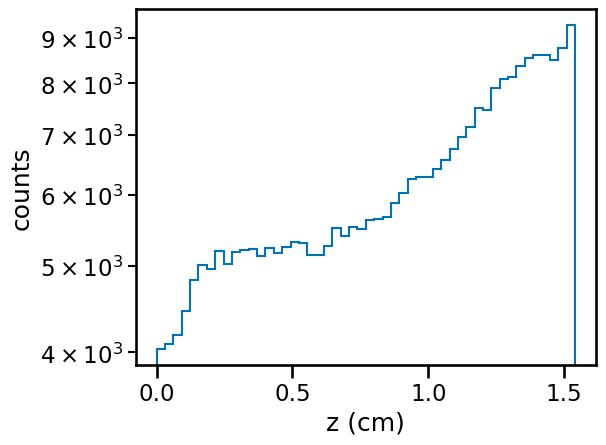

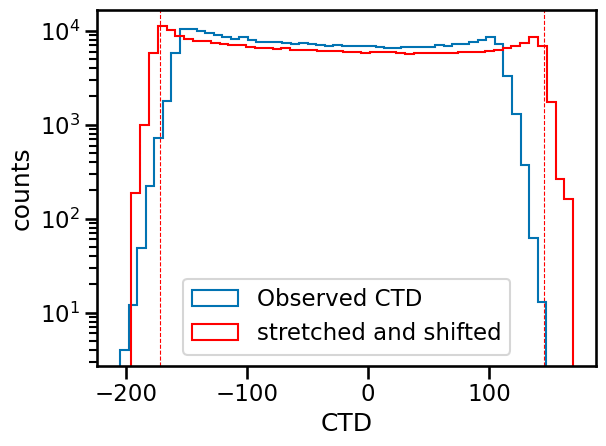

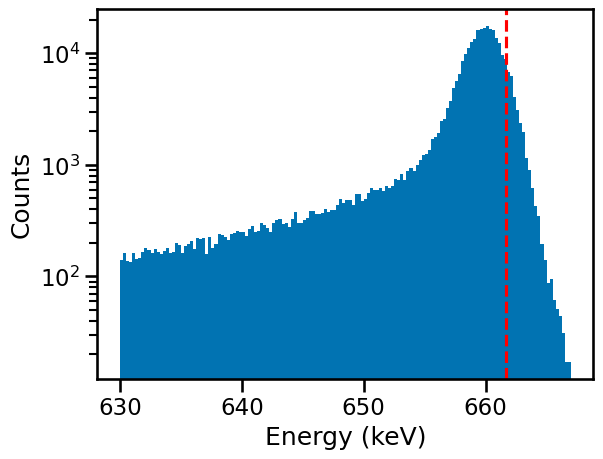

FWHM = 3.47
FWTM = 7.53


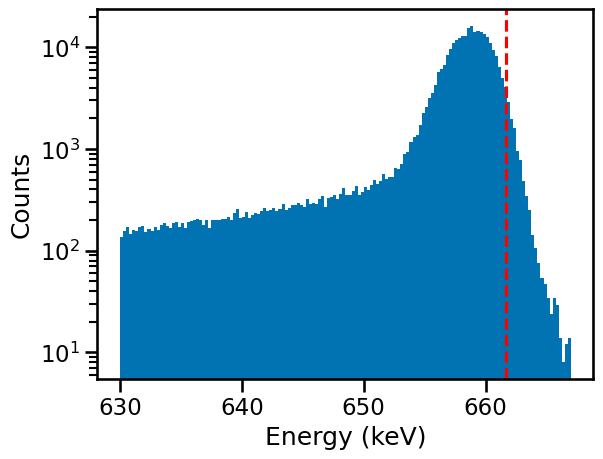

FWHM = 4.03
FWTM = 7.76


In [12]:
data_dict = {}
# for source in file_dict:
for source in ['Cs137']:
    emin = erange_dict[source][0]
    emax = erange_dict[source][1]
    
    string = source + 'allACDC_postLL1'
    
    ## Read in the dat files
    fullpaths = []
    for p in np.concatenate(file_dict[source]):
        fullpaths.append(datpath + 'postLL_2025/recalib/' + p)
    
    df = make_df_from_dat(fullpaths, e_min=emin, e_max=emax)
    df = df[
    ~df.iloc[:,5].isin([28, 5, 25])
]

    ### Run depth calibration

    ctd_obs_map = [[[] for p in range(37)] for n in range(37)]
    ctd_stretch_map = [[[] for p in range(37)] for n in range(37)]
    ctd_obs_flat = []
    ctd_stretch_flat = []

    for p in range(37):
        for n in range(37):
            ctd_obs, ctd_stretch, depth, depth_err, bad = calibrator.depth_from_timing_prob(p+1, n+1, df.loc[df.strip_p.eq(p+1)&df.strip_n.eq(n+1), 'time_p'], \
                                                                                       df.loc[df.strip_p.eq(p+1)&df.strip_n.eq(n+1), 'time_n'], \
                                                                                      df.loc[df.strip_p.eq(p+1)&df.strip_n.eq(n+1), 'energy_p'])
            df.loc[df.strip_p.eq(p+1)&df.strip_n.eq(n+1), 'z'] =  depth
            df.loc[df.strip_p.eq(p+1)&df.strip_n.eq(n+1), 'z_err'] =  depth_err
            df.loc[df.strip_p.eq(p+1)&df.strip_n.eq(n+1), 'bad'] =  bad
            ctd_obs_map[p][n] = ctd_obs[~bad]
            ctd_stretch_map[p][n] = ctd_stretch[~bad]
            ctd_obs_flat.append(ctd_obs[~bad])
            ctd_stretch_flat.append(ctd_stretch[~bad])

    ctd_obs_flat = np.concatenate(ctd_obs_flat)
    ctd_stretch_flat = np.concatenate(ctd_stretch_flat)
    data_dict[source] = df
    
    plt.figure()
    plt.hist(df["z"], bins=50, histtype = "step", range=(calibrator.zmin,calibrator.zmax))
    plt.yscale('log')
    plt.xlabel("z (cm)")
    plt.ylabel("counts")
    plt.tight_layout()
    plt.show()
    # plt.savefig(plot_dir + 'depth_' + string + '_prob.pdf')

    plt.figure()
    plt.hist(ctd_obs_flat, bins=50, histtype="step", label="Observed CTD")
    plt.hist(ctd_stretch_flat, bins=50, histtype="step", color='red', label="stretched and shifted")
    plt.axvline(np.max(sim_ctd), lw=0.8, color='red', ls='dashed', zorder=0)
    plt.axvline(np.min(sim_ctd), lw=0.8, color='red', ls='dashed', zorder=0)
    plt.yscale('log')
    plt.xlabel('CTD')
    plt.ylabel('counts')
    plt.tight_layout()
    plt.legend()
    plt.show()
    # plt.savefig(plot_dir + "CTD_" + string + ".pdf")
    
    bins = int((emax-emin) * 4)
    plt.figure()
    hist,binedges,_  = plt.hist(df['energy_p'][~df['bad'].values], bins=bins, range=(emin, emax))
    plt.axvline(source_dict[source], color='red', ls='dashed')
    plt.yscale('log')
    plt.xlabel('Energy (keV)')
    plt.ylabel('Counts')
    plt.show()
    
    fwhm, fwtm ,fwhm_err, fwtm_err = get_FWHM_FWTM(binedges[:-1], hist)
    print('FWHM = ' + str(round(fwhm, 2)))
    print('FWTM = ' + str(round(fwtm, 2)))

    plt.figure()
    hist,binedges,_  = plt.hist(df['energy_n'][~df['bad'].values], bins=binedges)
    plt.axvline(source_dict[source], color='red', ls='dashed')
    plt.yscale('log')
    plt.xlabel('Energy (keV)')
    plt.ylabel('Counts')
    plt.show()
    
    fwhm, fwtm,fwhm_err, fwtm_err = get_FWHM_FWTM(binedges[:-1], hist)

    print('FWHM = ' + str(round(fwhm, 2)))
    print('FWTM = ' + str(round(fwtm, 2)))


1286.8402548016156 2455.1370216590176


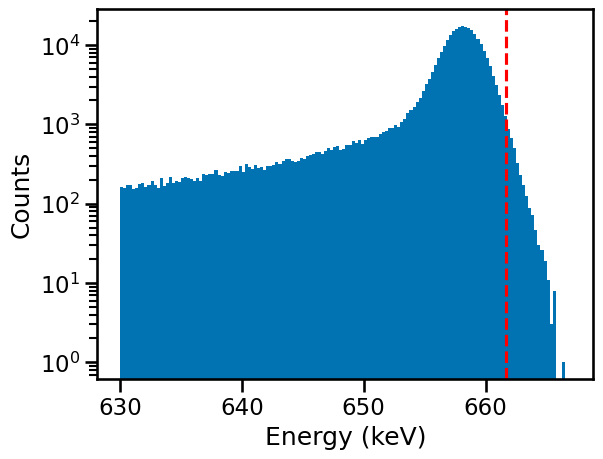

FWHM = 3.41
FWTM = 7.2


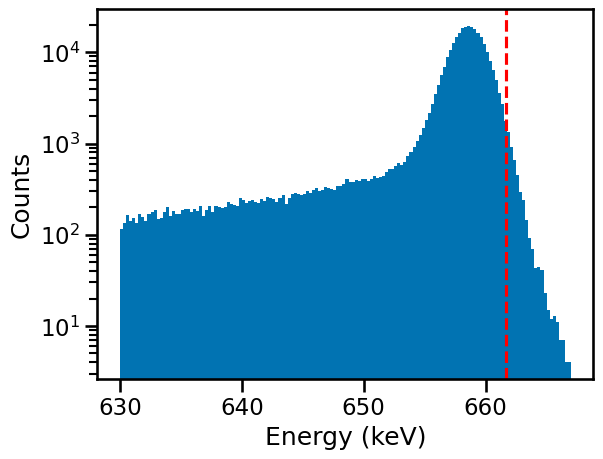

FWHM = 3.18
FWTM = 6.36


In [13]:
# for source in file_dict:
for source in ['Cs137']:
    
    emin = erange_dict[source][0]
    emax = erange_dict[source][1]

    string = source + 'allACDC_postLL'
    
    df = data_dict[source]

    escale = 1.0
    hscale= 1.0
    print(etrap_map.mean()*1000, htrap_map.mean()*1000)
    
    for p in range(37):
        for n in range(37):
            En_z = UnivariateSpline(depth_grid, 1.00346*h_cce(escale*etrap_map[p,n], hscale*htrap_map[p,n]))
            Ep_z = UnivariateSpline(depth_grid,  1.004315*e_cce(escale*etrap_map[p,n],  hscale*htrap_map[p,n]))

            depth = df.loc[df.strip_p.eq(p+1)&df.strip_n.eq(n+1), 'z'] # he compares CTD from simulation with CTD from data to get the depth which is the part I don't understand 
            energy_p = df.loc[df.strip_p.eq(p+1)&df.strip_n.eq(n+1), 'energy_p']
            energy_n = df.loc[df.strip_p.eq(p+1)&df.strip_n.eq(n+1), 'energy_n']
            df.loc[df.strip_p.eq(p+1)&df.strip_n.eq(n+1), 'depth_corrected_energy_p'] =  energy_p/Ep_z(depth)
            df.loc[df.strip_p.eq(p+1)&df.strip_n.eq(n+1), 'depth_corrected_energy_n'] =  energy_n/En_z(depth)

    bins = int((emax-emin) * 4)
    plt.figure()
    hist,binedges,_  = plt.hist(df['depth_corrected_energy_p'][~df['bad'].values], bins=bins, range=(emin, emax))
    plt.axvline(source_dict[source], color='red', ls='dashed')
    plt.yscale('log')
    plt.xlabel('Energy (keV)')
    plt.ylabel('Counts')
    plt.show()
    
    fwhm, fwtm,fwhm_err, fwtm_err = get_FWHM_FWTM(binedges[:-1], hist)
    print('FWHM = ' + str(round(fwhm, 2)))
    print('FWTM = ' + str(round(fwtm, 2)))

    plt.figure()
    hist,binedges,_  = plt.hist(df['depth_corrected_energy_n'][~df['bad'].values], bins=binedges)
    plt.axvline(source_dict[source], color='red', ls='dashed')
    plt.yscale('log')
    plt.xlabel('Energy (keV)')
    plt.ylabel('Counts')
    plt.show()
    
    fwhm, fwtm,fwhm_err, fwtm_err = get_FWHM_FWTM(binedges[:-1], hist)
    print('FWHM = ' + str(round(fwhm, 2)))
    print('FWTM = ' + str(round(fwtm, 2)))


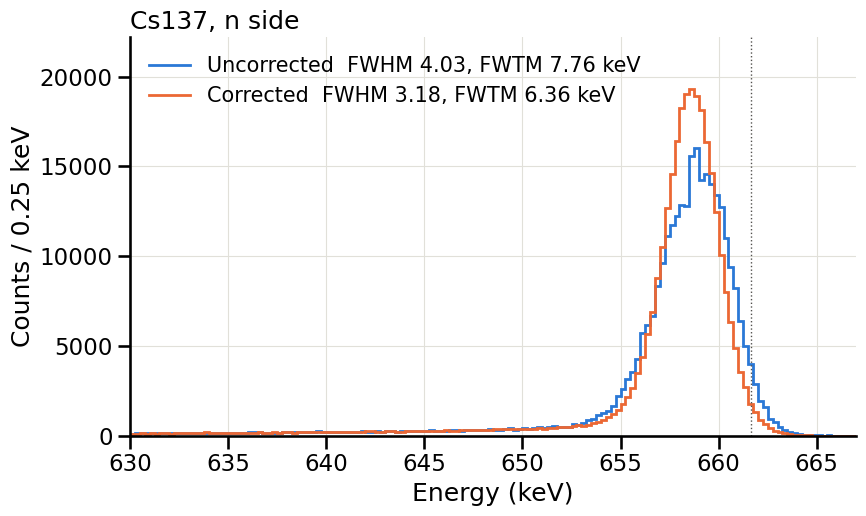

/Users/Sophie/Desktop/COSI/calibrations/Data/AnnealingStudies/trapping_notebooks/depth_helpers.py:88: UserWarning: 
The maximal number of iterations maxit (set to 20 by the program)
allowed for finding a smoothing spline with fp=s has been reached: s
too small.
There is an approximation returned but the corresponding weighted sum
of squared residuals does not satisfy the condition abs(fp-s)/s < tol.
  spline = UnivariateSpline(x, y-C, k=4)


Saved /Users/Sophie/Desktop/COSI/calibrations/Data/trapping_figures/Cs137_n_side_trapping_correction.gif


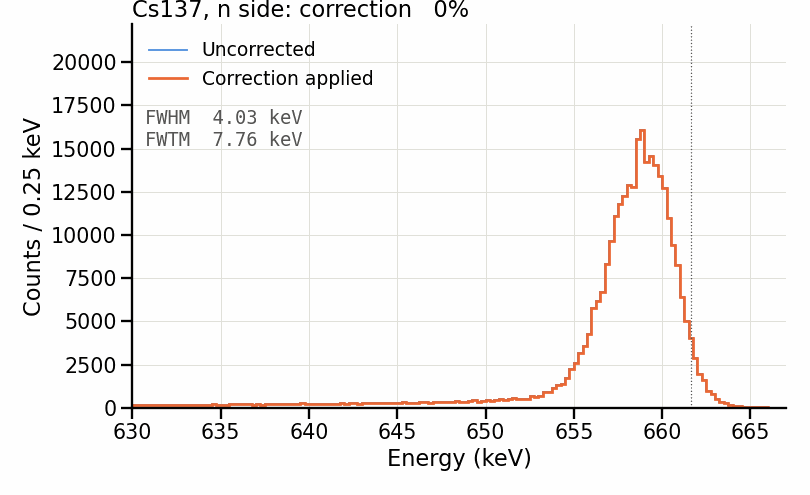

In [14]:
##################### Uncorrected vs. corrected photopeak: overlay + GIF #####################
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

SIDE = 'n'          # 'n' or 'p': which strip side's energies to show
LOG_Y = False       # log-scale counts (linear makes the FWHM change easiest to see)
N_MORPH = 40        # frames for the raw -> corrected transition
N_HOLD = 12         # frames held still at each end
gif_path = plot_dir + '%s_%s_side_trapping_correction.gif' % (source, SIDE)

COLOR_RAW = '#2a78d6'    # uncorrected
COLOR_CORR = '#eb6834'   # corrected
COLOR_INK = '#52514e'

mask = ~df['bad'].values
E_raw = df['energy_' + SIDE].values[mask]
E_corr = df['depth_corrected_energy_' + SIDE].values[mask]
good = np.isfinite(E_raw) & np.isfinite(E_corr)
E_raw, E_corr = E_raw[good], E_corr[good]

bins_anim = np.linspace(emin, emax, int((emax - emin) * 4) + 1)
centers = 0.5 * (bins_anim[:-1] + bins_anim[1:])

def resolution(energies):
    hist, _ = np.histogram(energies, bins=bins_anim)
    try:
        fwhm, fwtm, _, _ = get_FWHM_FWTM(centers, hist)
        return hist, fwhm, fwtm
    except Exception:
        return hist, np.nan, np.nan

h_raw, fwhm_raw, fwtm_raw = resolution(E_raw)
h_corr, fwhm_corr, fwtm_corr = resolution(E_corr)
ymax = 1.15 * max(h_raw.max(), h_corr.max())

def style(ax):
    ax.axvline(source_dict[source], color=COLOR_INK, ls=':', lw=1)
    ax.set_xlim(emin, emax)
    if LOG_Y:
        ax.set_yscale('log')
        ax.set_ylim(0.8, ymax * 2)
    else:
        ax.set_ylim(0, ymax)
    ax.set_xlabel('Energy (keV)')
    ax.set_ylabel('Counts / %.2f keV' % (bins_anim[1] - bins_anim[0]))
    ax.grid(True, color='#e1e0d9', lw=0.8)
    ax.set_axisbelow(True)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)

# ---- Static overlay ----
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.stairs(h_raw, bins_anim, color=COLOR_RAW, lw=2,
          label='Uncorrected  FWHM %.2f, FWTM %.2f keV' % (fwhm_raw, fwtm_raw))
ax.stairs(h_corr, bins_anim, color=COLOR_CORR, lw=2,
          label='Corrected  FWHM %.2f, FWTM %.2f keV' % (fwhm_corr, fwtm_corr))
style(ax)
ax.set_title('%s, %s side' % (source, SIDE), loc='left')
ax.legend(loc='upper left', frameon=False, fontsize='small')
plt.tight_layout()
plt.savefig(plot_dir + '%s_%s_side_trapping_correction.pdf' % (source, SIDE))
plt.show()

# ---- Animation: each event moves from its raw to its corrected energy ----
ease = lambda t: 0.5 - 0.5 * np.cos(np.pi * t)
fracs = np.concatenate([np.zeros(N_HOLD), ease(np.linspace(0, 1, N_MORPH)), np.ones(N_HOLD)])

fig, ax = plt.subplots(figsize=(9, 5.5))
style(ax)
ax.stairs(h_raw, bins_anim, color=COLOR_RAW, lw=1.5, alpha=0.8, label='Uncorrected')
moving = ax.stairs(h_raw, bins_anim, color=COLOR_CORR, lw=2.2, label='Correction applied')
ax.legend(loc='upper left', frameon=False, fontsize='small')
title = ax.set_title('', loc='left')
readout = ax.text(0.02, 0.78, '', transform=ax.transAxes, ha='left', va='top',
                  color=COLOR_INK, fontsize='small', family='monospace')
plt.tight_layout()

def update(k):
    f = fracs[k]
    hist, fwhm, fwtm = resolution((1. - f) * E_raw + f * E_corr)
    moving.set_data(hist)
    title.set_text('%s, %s side: correction %3d%%' % (source, SIDE, round(100 * f)))
    readout.set_text('FWHM %5.2f keV\nFWTM %5.2f keV' % (fwhm, fwtm))
    return moving, title, readout

anim = FuncAnimation(fig, update, frames=len(fracs), blit=False)
anim.save(gif_path, writer=PillowWriter(fps=15), dpi=90)
plt.close(fig)
print('Saved', gif_path)
display(Image(filename=gif_path))